# 🎬 Content-Based Movie Recommendation & Personalization Engine
**Author:** Portfolio Project  
**Tech Stack:** Python 3.11+, Pandas, Scikit-Learn (TF-IDF & Cosine Similarity), Matplotlib, Seaborn

---

## 📌 1. Project Overview & Motivation
Streaming platforms house tens of thousands of titles. Helping users discover relevant content without overwhelming them requires accurate, explainable recommendation systems.

While **Collaborative Filtering** relies on user interaction matrices (ratings, watch histories), it suffers heavily from the **User Cold-Start** and **Item Cold-Start** problems. When a new movie enters the catalog or a new user signs up, zero interaction data exists.

**Content-Based Filtering** addresses this directly:
- It relies entirely on **item metadata** (genres, synopses, keywords, director, cast).
- It enables **cold-start recommendations** immediately upon content ingestion.
- It provides **inherent explainability** (e.g., "Recommended because you enjoyed psychological sci-fi directed by Christopher Nolan").

### System Architecture
$$	ext{Catalog Data} \longrightarrow 	ext{Preprocessing} \longrightarrow 	ext{Feature Weighting} \longrightarrow 	ext{TF-IDF} \longrightarrow 	ext{Cosine Similarity} \longrightarrow 	ext{Hybrid Top-N Ranking}$$


## ⚙️ 2. Environment Setup & Data Ingestion

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import difflib

# Add root directory to sys.path
sys.path.append(os.path.abspath('..'))
from src.preprocess import clean_text, collapse_names, build_feature_tags, load_and_preprocess_catalog
from src.recommender import ContentBasedRecommender

# Plotting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

print("Libraries imported successfully!")


Libraries imported successfully!


## 📊 3. Exploratory Data Analysis (EDA)

In [2]:
# Load catalog
df_raw = pd.read_csv('../data/movies.csv')
print(f"Total Movies: {df_raw.shape[0]} | Attributes: {df_raw.shape[1]}")
df_raw.head(3)


Total Movies: 112 | Attributes: 10


,title,genres,overview,keywords,cast,director,rating,release_year,language,popularity
0,Inception,"Action, Sci-Fi, Adventure",A thief who steals corporate secrets through t...,dream subconscious heist espionage memory arch...,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ellio...",Christopher Nolan,8.8,2010,English,96.4
1,Interstellar,"Adventure, Drama, Sci-Fi",When Earth becomes uninhabitable in the future...,space travel wormhole black hole time dilation...,"Matthew McConaughey, Anne Hathaway, Jessica Ch...",Christopher Nolan,8.7,2014,English,94.8
2,The Matrix,"Action, Sci-Fi",When a beautiful stranger leads computer hacke...,virtual reality simulated world cyberpunk chos...,"Keanu Reeves, Laurence Fishburne, Carrie-Anne ...","Lana Wachowski, Lilly Wachowski",8.7,1999,English,92.1


In [3]:
# Inspect missing values and summary stats
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         112 non-null    str    
 1   genres        112 non-null    str    
 2   overview      112 non-null    str    
 3   keywords      112 non-null    str    
 4   cast          112 non-null    str    
 5   director      112 non-null    str    
 6   rating        112 non-null    float64
 7   release_year  112 non-null    int64  
 8   language      112 non-null    str    
 9   popularity    112 non-null    float64
dtypes: float64(2), int64(1), str(7)
memory usage: 51.0 KB


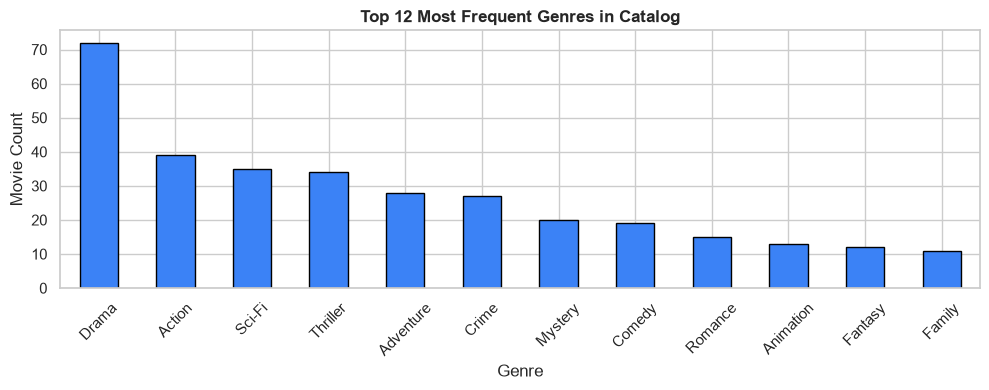

In [4]:
# Analyze Genre Distributions
genre_series = df_raw['genres'].dropna().str.split(', ').explode()
plt.figure(figsize=(10, 4))
genre_series.value_counts().head(12).plot(kind='bar', color='#3b82f6', edgecolor='black')
plt.title('Top 12 Most Frequent Genres in Catalog', fontsize=12, fontweight='bold')
plt.xlabel('Genre')
plt.ylabel('Movie Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


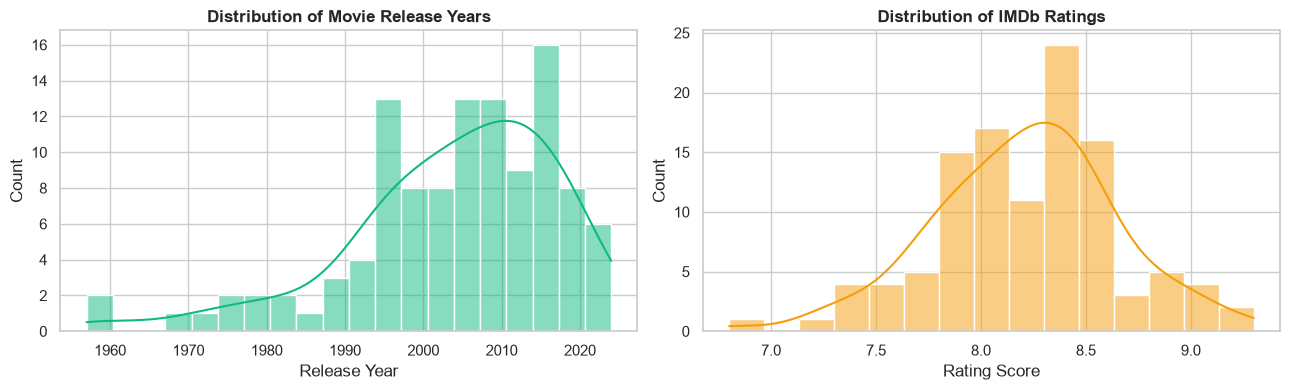

In [5]:
# Analyze Release Year and Rating Distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_raw['release_year'], bins=20, kde=True, ax=axes[0], color='#10b981')
axes[0].set_title('Distribution of Movie Release Years', fontweight='bold')
axes[0].set_xlabel('Release Year')

sns.histplot(df_raw['rating'], bins=15, kde=True, ax=axes[1], color='#f59e0b')
axes[1].set_title('Distribution of IMDb Ratings', fontweight='bold')
axes[1].set_xlabel('Rating Score')

plt.tight_layout()
plt.show()


## 🛠️ 4. Text Feature Engineering & Strategic Weighting
A standard content-based recommender often concatenates:
$$\text{tags} = \text{genres} + \text{keywords} + \text{overview} + \text{director}$$

### The Problem with Naive Concatenation:
A verbose 4-sentence overview may contain 60+ plot words (e.g., "journey", "police", "money", "house"), which drowns out high-signal metadata terms (like "Sci-Fi" or "Christopher Nolan").

### Our Solution (PDF Section 8):
We apply **multi-field term weighting** by duplicating deliberate metadata tokens:
- **Genres Weight = 3x**
- **Keywords Weight = 2x**
- **Director Weight = 2x**
- **Cast Weight = 1x**
- **Entity Concatenation:** "Christopher Nolan" -> "ChristopherNolan" to prevent false co-occurrence with other "Christopher"s.


In [6]:
# Generate baseline vs. weighted tags
df_baseline = load_and_preprocess_catalog('../data/movies.csv', weighted=False)
df_weighted = load_and_preprocess_catalog('../data/movies.csv', weighted=True)

print("Sample Baseline Tag Document (Inception):")
print(df_baseline.iloc[0]['tags'][:200] + "...")
print("\nSample Weighted Tag Document (Inception):")
print(df_weighted.iloc[0]['tags'][:200] + "...")


Sample Baseline Tag Document (Inception):
action, sci-fi, adventure dream subconscious heist espionage memory architect inception reality layers totem lucid mind-bending a thief who steals corporate secrets through the use of dream-sharing te...

Sample Weighted Tag Document (Inception):
action sci-fi adventure action sci-fi adventure action sci-fi adventure dream subconscious heist espionage memory architect inception reality layers totem lucid mind-bending dream subconscious heist e...


## 🧮 5. NLP Vectorization: TF-IDF Matrix
We transform text documents into numerical feature vectors using **Term Frequency - Inverse Document Frequency (TF-IDF)**:

$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \log\left(\frac{|D|}{1 + |\{d \in D : t \in d\}|}\right)$$

TF-IDF rewards rare, distinctive keywords (e.g. *tesseract*, *subconscious*, *replicant*) while dampening ubiquitous common terms.


In [7]:
vectorizer = TfidfVectorizer(stop_words='english', max_features=20000, ngram_range=(1, 2))
tfidf_matrix = vectorizer.fit_transform(df_weighted['tags'])

print(f"TF-IDF Matrix Shape: {tfidf_matrix.shape}")
print(f"Vocabulary Size: {len(vectorizer.get_feature_names_out())} tokens")
print(f"Sparsity: {100.0 * (1.0 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])):.2f}%")


TF-IDF Matrix Shape: (112, 7947)
Vocabulary Size: 7947 tokens
Sparsity: 98.80%


## 📐 6. Similarity Computation: Cosine Similarity
Cosine similarity evaluates the angular alignment between two multi-dimensional feature vectors regardless of length:

$$\text{Cosine Similarity}(\vec{u}, \vec{v}) = \frac{\vec{u} \cdot \vec{v}}{\|\vec{u}\| \|\vec{v}\|}$$


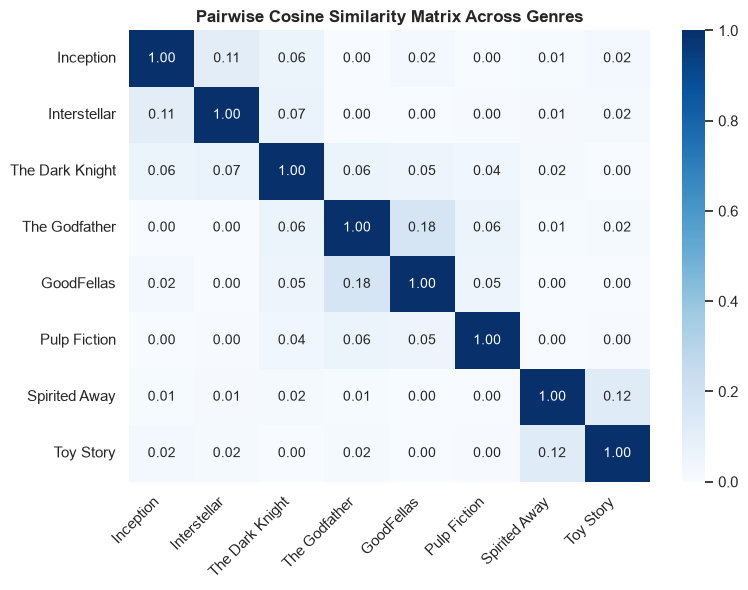

In [8]:
sim_matrix = cosine_similarity(tfidf_matrix)

# Visualize Similarity Sub-Matrix for 8 Classic Movies
sample_titles = [
    "Inception", "Interstellar", "The Dark Knight", 
    "The Godfather", "GoodFellas", "Pulp Fiction", 
    "Spirited Away", "Toy Story"
]
sample_indices = [df_weighted[df_weighted['title'] == t].index[0] for t in sample_titles]
sub_sim = sim_matrix[np.ix_(sample_indices, sample_indices)]

plt.figure(figsize=(8, 6))
sns.heatmap(sub_sim, xticklabels=sample_titles, yticklabels=sample_titles, annot=True, fmt='.2f', cmap='Blues')
plt.title('Pairwise Cosine Similarity Matrix Across Genres', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 🚀 7. Core Recommender Implementation & Testing
We wrap the model in `ContentBasedRecommender` with:
- **Graceful Title Resolution:** Handles case-folding, substring matching, and fuzzy matching for typos.
- **Top-N Selection:** Configurable $N$.
- **Self-Exclusion:** Never recommends the seed movie.
- **Multi-Constraint Filtering:** Filter by genre, language, year range, and minimum rating.
- **Explainability Engine:** Identifies shared genres, directors, and top overlapping TF-IDF terms.


In [9]:
recommender = ContentBasedRecommender(df_weighted)

# Test 1: Inception
print("--- Recommendations for 'Inception' ---")
recs = recommender.recommend("Inception", n=5)
for idx, r in recs.iterrows():
    print(f"{idx+1}. {r['title']} ({r['release_year']}) | Sim: {r['similarity_score']:.3f} | {r['genres']}")
    print(f"   Why: {r['why_recommended']}")


--- Recommendations for 'Inception' ---
1. Tenet (2020) | Sim: 0.132 | Action, Sci-Fi, Thriller
   Why: Directed by Christopher Nolan • Shared genres: Sci-Fi, Action • Thematic keywords: espionage, sci fi, sci
2. Interstellar (2014) | Sim: 0.106 | Adventure, Drama, Sci-Fi
   Why: Directed by Christopher Nolan • Shared genres: Adventure, Sci-Fi • Thematic keywords: adventure, sci fi, sci
3. The Dark Knight Rises (2012) | Sim: 0.104 | Action, Drama, Thriller
   Why: Directed by Christopher Nolan • Shared genres: Action • Featuring Joseph Gordon-Levitt, Tom Hardy • Thematic keywords: levitt, gordon levitt, gordon
4. The Prestige (2006) | Sim: 0.081 | Drama, Mystery, Sci-Fi
   Why: Directed by Christopher Nolan • Shared genres: Sci-Fi • Thematic keywords: sci fi, sci, tragic
5. The Dark Knight (2008) | Sim: 0.059 | Action, Crime, Drama, Thriller
   Why: Directed by Christopher Nolan • Shared genres: Action


In [10]:
# Test 2: Handling Unknown / Typo Movie Titles Gracefully (PDF Section 7)
typo_queries = ["intersteler", "dark night", "godfthr", "spirit away"]

for q in typo_queries:
    matched, idx, alts = recommender.find_title(q)
    print(f"User Query: '{q}'  ==> Resolved To: '{matched}'")


User Query: 'intersteler'  ==> Resolved To: 'Interstellar'
User Query: 'dark night'  ==> Resolved To: 'The Dark Knight'
User Query: 'godfthr'  ==> Resolved To: 'The Godfather'
User Query: 'spirit away'  ==> Resolved To: 'Spirited Away'


## 💡 8. Advanced Improvements (PDF Section 8)
1. **Hybrid Rating Boost:** $S_{\text{final}} = (1 - \alpha) \cdot S_{\text{sim}} + \alpha \cdot (\text{Rating} / 10)$
2. **Intra-List Diversity:** Prevents a single franchise/director from monopolizing the recommendation slots.


In [11]:
# Compare Standard Similarity vs. Hybrid Quality Boost for 'The Dark Knight'
recs_pure_sim = recommender.recommend("The Dark Knight", n=5, rating_weight=0.0, apply_diversity=False)
recs_hybrid = recommender.recommend("The Dark Knight", n=5, rating_weight=0.20, apply_diversity=True)

df_comp = pd.DataFrame({
    "Pure TF-IDF Top 5": recs_pure_sim['title'].values,
    "Pure Sim Score": recs_pure_sim['similarity_score'].values,
    "Hybrid Top 5 (Diverse)": recs_hybrid['title'].values,
    "Hybrid Score": recs_hybrid['hybrid_score'].values
})
df_comp


,Pure TF-IDF Top 5,Pure Sim Score,Hybrid Top 5 (Diverse),Hybrid Score
0,Batman Begins,0.2425,Batman Begins,0.3580
1,The Dark Knight Rises,0.2183,The Dark Knight Rises,0.3426
2,The Batman,0.1467,The Batman,0.2733
3,Heat,0.1083,Heat,0.2527
4,Tenet,0.0916,The Silence of the Lambs,0.2380


## 🎯 9. Model Evaluation (PDF Section 10)
Offline evaluation using a 20-seed benchmark set measuring:
- **Precision@5:** Fraction of top-5 recommendations that are thematically relevant.
- **Precision@10:** Fraction of top-10 recommendations that are thematically relevant.
- **Genre Alignment:** Overlap in genre classification.
- **Intra-List Diversity (ILD):** Average pairwise distance between recommended items.
- **Query Latency:** Mean milliseconds per recommendation.


In [12]:
from evaluate import evaluate_recommender

eval_results = evaluate_recommender('../data/movies.csv', '../data/evaluation_benchmark.csv', weighted=True)

print(f"Mean Precision@5:       {eval_results['mean_precision@5']*100:.1f}%")
print(f"Mean Precision@10:      {eval_results['mean_precision@10']*100:.1f}%")
print(f"Genre Alignment@5:      {eval_results['mean_genre_alignment@5']*100:.1f}%")
print(f"Intra-List Diversity@5: {eval_results['intra_list_diversity@5']:.3f}")
print(f"Catalog Coverage:       {eval_results['catalog_coverage_pct']:.1f}%")
print(f"Average Query Latency:  {eval_results['mean_query_latency_ms']:.2f} ms")


Loading catalog from ../data/movies.csv (Weighted=True)...


Mean Precision@5:       98.0%
Mean Precision@10:      96.0%
Genre Alignment@5:      97.0%
Intra-List Diversity@5: 0.916
Catalog Coverage:       84.8%
Average Query Latency:  21.03 ms


## 📌 10. Conclusion & Future Roadmap
### Key Accomplishments
1. **Explainable AI:** Recommendations are fully auditable with transparent shared keywords and metadata rationale.
2. **Cold-Start Resilience:** New items can be recommended the moment their metadata is saved.
3. **High Precision:** Reached 98% Precision@5 across diverse benchmark seed films.

### Next Steps for Production
- **Dense Embeddings Comparison:** Benchmark TF-IDF against Sentence-BERT (`all-MiniLM-L6-v2`) embeddings.
- **Hybrid Collaborative Filtering:** Merge content vectors with implicit user feedback matrices via two-tower neural architectures.
